# 01 · Base de conhecimento e busca
Monta a base (um trecho por artigo de lei, sempre com fonte), mede **recall@1** e **recall@3**
de três buscadores e escolhe o **limiar** de score abaixo do qual o sistema responde "não consta".

> O limiar é escolhido nas perguntas de **treino** (`avaliacao/lora_treino.jsonl`) e só depois
> conferido no **teste**, para não "colar" no conjunto de avaliação.

In [1]:
# Preparação do ambiente (Colab ou local)
import os, sys, subprocess
REPO_URL = "https://github.com/giuliano10/GS-GENENERATIVE-AI.git"
SUBPASTA = "assistente-acessibilidade-calcadas"   # pasta do projeto dentro do repositório

if "google.colab" in sys.modules:
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", REPO_URL, "/content/repo"], check=True)
    else:   # mesma sessão de outro notebook: atualiza o código
        subprocess.run(["git", "-C", "/content/repo", "pull", "-q"])
    os.chdir(os.path.join("/content/repo", SUBPASTA))
    # O Colab já traz torch, transformers, numpy etc. Instalamos SÓ o que falta, sem fixar
    # versões: reinstalar o torch com a sessão aberta quebra o "import torch".
    import importlib.util
    faltando = [pip for mod, pip in [("peft", "peft"), ("accelerate", "accelerate"),
                ("sentence_transformers", "sentence-transformers"), ("fastapi", "fastapi"),
                ("httpx", "httpx"), ("tabulate", "tabulate"), ("bs4", "beautifulsoup4"),
                ("lxml", "lxml")] if importlib.util.find_spec(mod) is None]
    # O torchao que vem no Colab é antigo e faz o peft recusar o import; o projeto não o usa.
    if importlib.util.find_spec("torchao") is not None:
        subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"])
    if faltando:
        print("Instalando:", faltando)
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltando],
                           capture_output=True, text=True)
        if r.returncode != 0:
            print(r.stdout[-3000:], r.stderr[-3000:])
            raise RuntimeError("Falha no pip install (detalhes acima)")
    # Cada notebook do Colab roda numa máquina separada: os resultados passam de um notebook
    # para o outro por uma pasta no Google Drive.
    from google.colab import drive
    drive.mount("/content/drive")
    PERSIST = "/content/drive/MyDrive/assistente-calcadas-resultados"
    os.makedirs(PERSIST, exist_ok=True)
    subprocess.run(["cp", "-r", f"{PERSIST}/.", "."])
    print("Resultados anteriores trazidos do Drive:", sorted(os.listdir(PERSIST)))
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Pasta do projeto:", os.getcwd())

Mounted at /content/drive
Resultados anteriores trazidos do Drive: []
Pasta do projeto: /content/repo/assistente-acessibilidade-calcadas


## 1. Base de conhecimento

In [2]:
from src.base_conhecimento import coletar, montar, carregar_trechos, ler_fontes
from src.config import ARQ_TRECHOS
if not ARQ_TRECHOS.exists():      # a base já vem pronta no repositório; isto só refaz se faltar
    coletar(); montar()
trechos = carregar_trechos()
print(len(trechos), "trechos")
trechos[0]

238 trechos


{'id': 'L10098-art1',
 'fonte_id': 'L10098',
 'fonte': 'Lei nº 10.098/2000 (Lei da Acessibilidade)',
 'artigo': 'Art. 1',
 'secao': '',
 'texto': 'Art. 1º Esta Lei estabelece normas gerais e critérios básicos para a promoção da acessibilidade das pessoas portadoras de deficiência ou com mobilidade reduzida, mediante a supressão de barreiras e de obstáculos nas vias e espaços públicos, no mobiliário urbano, na construção e reforma de edifícios e nos meios de transporte e de comunicação.',
 'url': 'https://www.planalto.gov.br/ccivil_03/leis/l10098.htm'}

In [3]:
import pandas as pd
fontes = pd.DataFrame(ler_fontes())
n = pd.Series([t["fonte_id"] for t in trechos]).value_counts().rename("n_trechos")
tabela = fontes.set_index("id").join(n)[["titulo", "esfera", "formato", "licenca", "artigos", "n_trechos", "url"]]
tabela.to_csv("base/tabela_base.csv")
tabela

,titulo,esfera,formato,licenca,artigos,n_trechos,url
id,,,,,,,
L10098,Lei nº 10.098/2000 (Lei da Acessibilidade),federal,HTML,Domínio público (Lei 9.610/98 art. 8º IV),,33,https://www.planalto.gov.br/ccivil_03/leis/l10...
D5296,Decreto nº 5.296/2004 (regulamenta as Leis 10....,federal,HTML,Domínio público (Lei 9.610/98 art. 8º IV),1-27,41,https://www.planalto.gov.br/ccivil_03/_ato2004...
L13146,Lei nº 13.146/2015 (Lei Brasileira de Inclusão),federal,HTML,Domínio público (Lei 9.610/98 art. 8º IV),1-3;46-62,27,https://www.planalto.gov.br/ccivil_03/_ato2015...
L9503,Lei nº 9.503/1997 (Código de Trânsito Brasileiro),federal,HTML,Domínio público (Lei 9.610/98 art. 8º IV),29;68-71;181;193;214;254,16,https://www.planalto.gov.br/ccivil_03/leis/l95...
L12587,Lei nº 12.587/2012 (Política Nacional de Mobil...,federal,HTML,Domínio público (Lei 9.610/98 art. 8º IV),,38,https://www.planalto.gov.br/ccivil_03/_ato2011...
SP-D59671,Decreto Municipal nº 59.671/2020 (calçadas – S...,municipal,HTML,Domínio público (Lei 9.610/98 art. 8º IV),,51,https://legislacao.prefeitura.sp.gov.br/leis/d...
SP-L16673,Lei Municipal nº 16.673/2017 (Estatuto do Pede...,municipal,HTML,Domínio público (Lei 9.610/98 art. 8º IV),,32,https://legislacao.prefeitura.sp.gov.br/leis/l...


In [4]:
import numpy as np
tam = np.array([len(t["texto"]) for t in trechos])
print(f"caracteres por trecho: mediana {np.median(tam):.0f}, p90 {np.percentile(tam, 90):.0f}, máx {tam.max()}")

caracteres por trecho: mediana 684, p90 1384, máx 1498


## 2. Conjuntos de perguntas

In [5]:
from src.avaliacao import carregar_jsonl
from src.config import ARQ_TESTE, ARQ_TREINO
teste, treino = carregar_jsonl(ARQ_TESTE), carregar_jsonl(ARQ_TREINO)
assert not {c["pergunta"] for c in teste} & {c["pergunta"] for c in treino}, "teste e treino se sobrepõem!"
ids = {t["id"] for t in trechos}
for c in teste + treino:
    assert set(c["trechos_gabarito"]) <= ids, (c["id"], c["trechos_gabarito"])
for nome, cj in [("teste", teste), ("treino", treino)]:
    print(nome, pd.Series([c["tipo"] for c in cj]).value_counts().to_dict())

teste {'consta': 45, 'nao_consta': 15}
treino {'consta': 47, 'nao_consta': 15}


## 3. Recall@1 e Recall@3 (conjunto de teste, perguntas que constam)

In [6]:
from sentence_transformers import SentenceTransformer
from src.busca import Buscador, recall_at_k
from src.config import EMB_ID
emb = SentenceTransformer(EMB_ID)
buscadores = {m: Buscador(trechos, modo=m, modelo_emb=emb) for m in ["tfidf", "denso", "hibrido"]}
linhas = [{"buscador": m, "recall@1": recall_at_k(b, teste, 1), "recall@3": recall_at_k(b, teste, 3)}
          for m, b in buscadores.items()]
recall = pd.DataFrame(linhas).round(3)
recall.to_csv("avaliacao/busca_recall.csv", index=False)
recall

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

,buscador,recall@1,recall@3
0,tfidf,0.489,0.822
1,denso,0.667,0.844
2,hibrido,0.622,0.978


In [7]:
# Perguntas em que o trecho certo NÃO veio no top-3 do buscador híbrido
b = buscadores["hibrido"]
for c in teste:
    if c["tipo"] != "consta": continue
    top = b.buscar(c["pergunta"], 3)
    if not {r["id"] for r in top} & set(c["trechos_gabarito"]):
        print(c["id"], c["pergunta"]); print("   esperado:", c["trechos_gabarito"]); print("   veio:", [r["id"] for r in top])

T24 Qual a iluminação mínima exigida nas calçadas pelo Estatuto do Pedestre?
   esperado: ['SP-L16673-art11']
   veio: ['SP-L16673-art1', 'SP-D59671-art26', 'SP-L16673-art6']


## 4. Limiar de "não consta" (escolhido no treino)

limiar escolhido: {'limiar': 0.6216, 'barra_nao_consta': 0.7333333333333333, 'passa_respondiveis': 1.0, 'f1': 0.846153846153846}


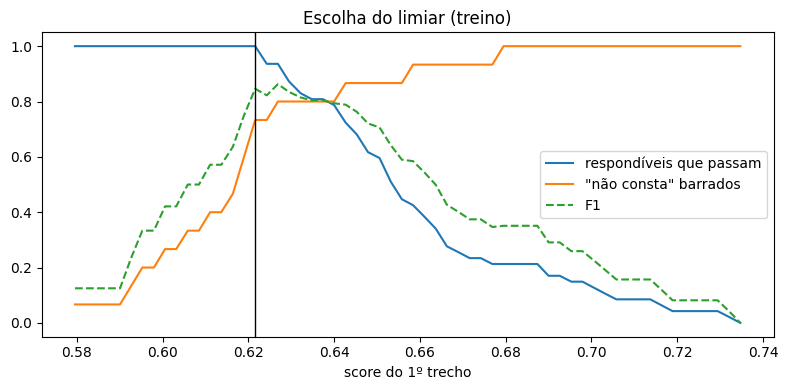

145

In [8]:
import json, matplotlib.pyplot as plt
from src.busca import varrer_limiar, escolher_limiar
from src.config import ARQ_LIMIAR
varredura = pd.DataFrame(varrer_limiar(b, treino))
escolha = escolher_limiar(varredura.to_dict("records"))
print("limiar escolhido:", escolha)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(varredura.limiar, varredura.passa_respondiveis, label="respondíveis que passam")
ax.plot(varredura.limiar, varredura.barra_nao_consta, label='"não consta" barrados')
ax.plot(varredura.limiar, varredura.f1, "--", label="F1")
ax.axvline(escolha["limiar"], color="k", lw=1); ax.set_xlabel("score do 1º trecho"); ax.legend(); ax.set_title("Escolha do limiar (treino)")
plt.tight_layout(); plt.savefig("avaliacao/limiar.png", dpi=120); plt.show()

ARQ_LIMIAR.write_text(json.dumps({"limiar": escolha["limiar"], "buscador": "hibrido", **escolha}, indent=2))

In [9]:
# Conferência no TESTE com o limiar fixado
sc = [(c["tipo"], b.buscar(c["pergunta"], 1)[0]["score"]) for c in teste]
lim = escolha["limiar"]
print(f'respondíveis que passam: {np.mean([s >= lim for t, s in sc if t == "consta"]):.1%}')
print(f'"não consta" barrados : {np.mean([s <  lim for t, s in sc if t == "nao_consta"]):.1%}')

respondíveis que passam: 95.6%
"não consta" barrados : 20.0%


In [10]:
# Salva os resultados no Google Drive (para o próximo notebook usar)
import shutil
FIXOS = {"casos_teste.jsonl", "lora_treino.jsonl", ".gitkeep"}
if "google.colab" in sys.modules:
    for pasta in ["avaliacao", "modelos"]:
        if os.path.exists(pasta):
            shutil.copytree(pasta, os.path.join(PERSIST, pasta), dirs_exist_ok=True,
                            ignore=lambda d, nomes: [n for n in nomes if n in FIXOS or n.endswith("_ckpt")])
    print("Salvo no Drive:", {p: sorted(os.listdir(os.path.join(PERSIST, p)))
                              for p in os.listdir(PERSIST) if os.path.isdir(os.path.join(PERSIST, p))})

Salvo no Drive: {'avaliacao': ['busca_recall.csv', 'limiar.json', 'limiar.png']}
